# 27 - Pell-Fermat : l'équation $x^2 - d\,y^2 = 1$, ses fractions continues et son unité fondamentale

Le carnet [11](11-corps-quadratiques-reciprocite-quadratique.ipynb) a étudié les corps quadratiques **imaginaires** $\mathbb{Q}(\sqrt{-d})$ : leurs unités sont en nombre **fini** — les racines de l'unité, rien de plus — et le nombre de classes y gouverne tout. En passant au signe opposé, aux corps quadratiques **réels** $\mathbb{Q}(\sqrt{d})$, un phénomène nouveau apparaît : le groupe des unités y est **infini**, engendré par une seule d'entre elles, l'**unité fondamentale**. L'équation de **Pell-Fermat**
$$x^2 - d\,y^2 = 1$$
n'est rien d'autre que l'équation de cette unité : ses solutions *sont* les unités de $\mathbb{Z}[\sqrt{d}]$ de norme $1$. Le carnet [15](15-quatre-carres-lagrange.ipynb) a déjà rencontré l'identité de **Brahmagupta-Fibonacci**, qui compose deux solutions en une troisième ; c'est la loi de groupe dont ce carnet exploite la structure.

Le fil calculatoire, en arithmétique `stdlib` pure :

1. **L'équation, et l'obstruction triviale** — $d$ carré parfait : aucune solution non triviale ; $d$ non carré : toujours une, mais d'une taille imprévisible.
2. **La fraction continue de $\sqrt{d}$** — l'algorithme $(m, \delta, a)$ de Lagrange, sa période, et le palindrome de Galois.
3. **Les convergents** — le théorème d'indice : la solution de $x^2 - d\,y^2 = -1$ tombe au convergent $p_{\ell-1}$, celle de $+1$ au convergent $p_{2\ell-1}$.
4. **Le théorème central, mesuré** — la période est **impaire** si et seulement si l'équation de Pell **négative** $x^2 - d\,y^2 = -1$ est soluble.
5. **Le critère de Legendre** — pour $d$ premier, la solubilité de la Pell négative équivaut à $d \equiv 1 \pmod 4$ ; et pourquoi ce critère cesse d'être suffisant pour les composés.
6. **L'unité fondamentale** — Brahmagupta compose les solutions, leurs puissances les épuisent, et le groupe obtenu est cyclique infini (le rang $1$ du théorème des unités de Dirichlet).
7. **Exemples guidés résolus et exercices** — trois de chaque, dans la convention de la série.

*Sources primaires* : Fermat, lettre à Wallis (février 1657) — l'énoncé du défi ; Lagrange, *Solution d'un problème d'arithmétique* (1766-1770) — la preuve de solubilité universelle ; Bhāskara II, *Bījagaṇita* (XIIe siècle) — la méthode **chakravala** (« la roue »), l'algorithme cyclique qui précède Lagrange de six siècles ; H. W. Lenstra Jr., « Solving the Pell Equation », *Notices of the AMS* **49** (2002) — la mise au point moderne, et l'histoire du problème des bœufs d'Archimède qui se ramène à une telle équation.

## 1. L'équation, et l'obstruction triviale

On cherche des entiers $x, y$ avec $y \neq 0$ vérifiant $x^2 - d\,y^2 = 1$. Deux remarques suffisent à cadrer le problème.

- Si $d = a^2$ est un **carré parfait**, alors $x^2 - (ay)^2 = 1$ se factorise en $(x - ay)(x + ay) = 1$ : deux entiers de produit $1$ valent $\pm 1$, d'où $y = 0$. **Aucune solution non triviale** — l'obstruction est complète et élémentaire.
- Si $d$ n'est **pas** un carré, l'équation admet **toujours** une solution non triviale. C'est le théorème de Lagrange (1766), et c'est loin d'être évident : on demande à une forme quadratique indéfinie de représenter exactement $1$, ce qu'aucun argument de comptage ne garantit.

Reste la question qui fait tout l'intérêt du sujet : **quelle taille** a la plus petite solution ? La première cellule la mesure par balayage naïf sur les petits $d$ — le balayage ne passe pas l'échelle, mais il donne l'étalon.

In [1]:
import math

def est_carre(n):
    """Vrai si n est un carre parfait."""
    return math.isqrt(n) ** 2 == n


def pell_balayage(d, limite=10**7):
    """Plus petite solution de x^2 - d y^2 = 1 par balayage sur y.

    Ne passe pas l'echelle : pour d = 61 il faudrait atteindre y = 226 153 980.
    Sert d'etalon pour les petits d.
    """
    for y in range(1, limite):
        cible = 1 + d * y * y
        x = math.isqrt(cible)
        if x * x == cible:
            return x, y
    return None


print(f"{'d':>3} {'x1':>12} {'y1':>12}")
for d in range(2, 17):
    if est_carre(d):
        continue
    x1, y1 = pell_balayage(d)
    print(f"{d:>3} {x1:>12} {y1:>12}")

  d           x1           y1
  2            3            2
  3            2            1
  5            9            4
  6            5            2
  7            8            3
  8            3            1
 10           19            6
 11           10            3
 12            7            2
 13          649          180
 14           15            4
 15            4            1


### Lecture du résultat

La colonne $x_1$ est **erratique**. $d = 3$ donne la solution minuscule $(2, 1)$, $d = 2$ donne $(3, 2)$ — puis $d = 13$ saute à $(649, 180)$, et l'on verra en section 6 que $d = 61$ exige $x_1 = 1\,766\,319\,049$, dix chiffres pour un paramètre à deux. Aucune monotonie, aucune formule fermée : la taille de la solution minimale est gouvernée par le développement en fraction continue de $\sqrt{d}$, et par lui seul.

Le balayage naïf, lui, est déjà hors d'échelle sur ces petits cas : pour $d = 61$ il faudrait énumérer $y$ jusqu'à $226\,153\,980$, et la solution de $d = 109$ (exercice 1) a quinze chiffres. Il faut un algorithme — il vient de l'analyse, pas de l'arithmétique.

## 2. La fraction continue de $\sqrt{d}$

Tout irrationnel quadratique a un développement en fraction continue **périodique** à partir d'un certain rang ; pour $\sqrt{d}$ la période commence immédiatement :
$$\sqrt{d} = [a_0; \overline{a_1, a_2, \ldots, a_\ell}] \qquad \text{avec } a_0 = \lfloor \sqrt{d} \rfloor.$$
L'algorithme de Lagrange le calcule par une récurrence sur trois entiers $(m_k, \delta_k, a_k)$ — c'est la forme que l'on implémente, la plus stable numériquement (elle ne manipule que des entiers) :
$$m_{k+1} = \delta_k a_k - m_k, \qquad \delta_{k+1} = \frac{d - m_{k+1}^2}{\delta_k}, \qquad a_{k+1} = \left\lfloor \frac{a_0 + m_{k+1}}{\delta_{k+1}} \right\rfloor$$
partant de $m_0 = 0$, $\delta_0 = 1$, $a_0 = \lfloor\sqrt{d}\rfloor$.

Un point de terminaison est nécessaire, et il existe un critère **canonique** : la période se referme exactement au premier terme valant $2a_0$. C'est ce critère qu'utilise la cellule, plutôt qu'un test sur le triplet d'état — ce dernier ne se referme jamais, $m = 0$ n'apparaissant qu'à l'état initial.

In [2]:
def periode_sqrt(d):
    """Periode du developpement en fraction continue de sqrt(d), d non carre.

    Algorithme de Lagrange sur (m, delta, a) ; terminaison canonique au
    premier terme a = 2*a0.
    """
    a0 = math.isqrt(d)
    m, delta, a = 0, 1, a0
    periode = []
    while True:
        m = delta * a - m
        delta = (d - m * m) // delta
        a = (a0 + m) // delta
        periode.append(a)
        if a == 2 * a0:
            return periode


print(f"{'d':>4} {'a0':>3}  {'periode':<34} {'l':>3}")
for d in [2, 3, 5, 6, 7, 13, 23, 29, 43, 61, 97, 109]:
    per = periode_sqrt(d)
    texte = "[" + ", ".join(str(a) for a in per) + "]"
    print(f"{d:>4} {math.isqrt(d):>3}  {texte:<34} {len(per):>3}")

   d  a0  periode                              l
   2   1  [2]                                  1
   3   1  [1, 2]                               2
   5   2  [4]                                  1
   6   2  [2, 4]                               2
   7   2  [1, 1, 1, 4]                         4
  13   3  [1, 1, 1, 1, 6]                      5
  23   4  [1, 3, 1, 8]                         4
  29   5  [2, 1, 1, 2, 10]                     5
  43   6  [1, 1, 3, 1, 5, 1, 3, 1, 1, 12]     10
  61   7  [1, 4, 3, 1, 2, 2, 1, 3, 4, 1, 14]  11
  97   9  [1, 5, 1, 1, 1, 1, 1, 1, 5, 1, 18]  11
 109  10  [2, 3, 1, 2, 4, 1, 6, 6, 1, 4, 2, 1, 3, 2, 20]  15


### Lecture du résultat

Deux régularités sautent aux yeux, et toutes deux sont des théorèmes.

La première est le **palindrome de Galois** : la période, privée de son dernier terme $2a_0$, se lit identiquement dans les deux sens. Pour $\sqrt{23}$ : $[1, 3, 1]$ ; pour $\sqrt{61}$ : $[1, 4, 3, 1, 2, 2, 1, 3, 4, 1]$. Ce n'est pas un hasard des exemples — c'est une conséquence de la théorie de Galois pour les irrationnels quadratiques, et la section 7 la vérifiera sur toute une plage.

La seconde est la **parité** de $\ell$ : elle est **impaire** pour $d = 2, 5, 13, 29, 61, 97, 109$ (longueurs $1, 1, 5, 5, 11, 11, 15$) et **paire** pour $d = 3, 6, 7, 23, 43$ (longueurs $2, 2, 4, 4, 10$). Cette parité n'est pas un détail combinatoire : c'est la clé de la section 4, elle décide si l'équation $x^2 - d\,y^2 = -1$ a une solution.

## 3. Les convergents, et où tombent les solutions

Les convergents $p_k/q_k$ de $\sqrt{d}$ sont les meilleures approximations rationnelles du nombre, et ils se calculent depuis les termes de la fraction continue par la récurrence classique :
$$p_{-1} = 1,\ q_{-1} = 0, \qquad p_k = a_k\,p_{k-1} + p_{k-2}, \qquad q_k = a_k\,q_{k-1} + q_{k-2}.$$

Leur intérêt pour Pell-Fermat tient à un théorème d'indice, que l'on va lire directement dans les valeurs de la forme $p_k^2 - d\,q_k^2$ :

- au convergent d'indice $\ell - 1$ (le dernier avant que la période ne se referme), la forme vaut $(-1)^\ell$ — donc $-1$ **exactement quand la période est impaire** ;
- au convergent d'indice $2\ell - 1$ elle vaut $+1$ ; mais la solution **minimale** de l'équation de Pell est atteinte plus tôt : c'est $p_{\ell-1}$ quand $\ell$ est **pair** (où la forme vaut déjà $+1$), et seulement $p_{2\ell-1}$ quand $\ell$ est impair.

Le cas $d = 61$, période de longueur $\ell = 11$, est le plus parlant : la solution de $-1$ tombe en $k = 10$ et celle de $+1$ en $k = 21$.

In [3]:
def convergents_sqrt(d, nmax):
    """Liste des convergents (p_k, q_k) de sqrt(d) pour k = 0..nmax."""
    a0 = math.isqrt(d)
    per = periode_sqrt(d)
    liste = []
    p_m1, q_m1, p, q = 1, 0, a0, 1
    liste.append((p, q))
    for k in range(1, nmax + 1):
        a = per[(k - 1) % len(per)]
        p, q, p_m1, q_m1 = a * p + p_m1, a * q + q_m1, p, q
        liste.append((p, q))
    return liste


d = 61
per = periode_sqrt(d)
l = len(per)
print(f"sqrt({d}) = [{math.isqrt(d)}; {', '.join(map(str, per))}]  (l = {l})")
print(f"{'k':>3} {'p_k':>14} {'q_k':>12} {'p^2 - 61 q^2':>14}")
for k, (p, q) in enumerate(convergents_sqrt(d, 2 * l - 1)):
    forme = p * p - d * q * q
    marque = ""
    if k == l - 1:
        marque = "   <- indice l-1"
    elif k == 2 * l - 1:
        marque = "   <- indice 2l-1 : solution minimale"
    print(f"{k:>3} {p:>14} {q:>12} {forme:>14}{marque}")

sqrt(61) = [7; 1, 4, 3, 1, 2, 2, 1, 3, 4, 1, 14]  (l = 11)
  k            p_k          q_k   p^2 - 61 q^2
  0              7            1            -12
  1              8            1              3
  2             39            5             -4
  3            125           16              9
  4            164           21             -5
  5            453           58              5
  6           1070          137             -9
  7           1523          195              4
  8           5639          722             -3
  9          24079         3083             12
 10          29718         3805             -1   <- indice l-1
 11         440131        56353             12
 12         469849        60158             -3
 13        2319527       296985              4
 14        7428430       951113             -9
 15        9747957      1248098              5
 16       26924344      3447309             -5
 17       63596645      8142716              9
 18       90520989     11590025 

### Lecture du résultat

La colonne de droite ne prend que trois valeurs : $\pm 1$ et un résidu borné — la forme oscille sans jamais s'éloigner. Et les deux indices annoncés tombent exactement où le théorème le dit : $k = 10 = \ell - 1$ donne $p_{10}^2 - 61\,q_{10}^2 = -1$ avec $(p_{10}, q_{10}) = (29\,718, 3\,805)$, puis $k = 21 = 2\ell - 1$ donne $+1$ avec $(1\,766\,319\,049, 226\,153\,980)$ — la solution minimale, celle que le balayage naïf n'aurait jamais atteinte.

Le rapport entre les deux est la seconde moitié de l'histoire : *élever au carré* la solution de $-1$ la transforme en solution de $+1$. En langage de corps quadratiques, $\left(29\,718 + 3\,805\sqrt{61}\right)^2 = 1\,766\,319\,049 + 226\,153\,980\sqrt{61}$ — le carré d'une unité de norme $-1$ est une unité de norme $+1$. C'est cette structure de groupe que la section 6 exploite.

## 4. Le théorème central : la période est impaire si et seulement si Pell négative est soluble

Les sections 2 et 3 ont exhibé deux séries de faits séparés. Le théorème les soude :

> **Théorème.** Soit $d > 0$ non carré, et $\ell$ la longueur de la période de $\sqrt{d}$. L'équation de Pell **négative** $x^2 - d\,y^2 = -1$ admet une solution entière si et seulement si $\ell$ est **impaire**.

La raison est déjà visible dans la section 3 : la forme $p_{\ell-1}^2 - d\,q_{\ell-1}^2$ vaut $(-1)^\ell$. Si $\ell$ est impair, ce convergent **est** une solution de $-1$ ; si $\ell$ est pair, aucune solution de $-1$ ne peut apparaître, car la théorie des convergents épuise les approximations suffisamment bonnes, et une solution de $-1$ en serait une.

La cellule vérifie le théorème sur toute la plage $2 \leq d \leq 200$ (les carrés exclus), puis affiche le témoin de chaque cas.

In [4]:
def pell_minimale(d, cible):
    """Plus petite solution x, y > 0 de x^2 - d y^2 = cible (cible = +1 ou -1)."""
    for k in range(4 * len(periode_sqrt(d)) + 10):
        p, q = convergents_sqrt(d, k)[k]
        if q > 0 and p * p - d * q * q == cible:
            return p, q
    return None


concordances, ecarts = 0, []
for d in range(2, 201):
    if est_carre(d):
        continue
    l = len(periode_sqrt(d))
    soluble = pell_minimale(d, -1) is not None
    if (l % 2 == 1) == soluble:
        concordances += 1
    else:
        ecarts.append(d)

print(f"theoreme sur 2 <= d <= 200 : {concordances} concordances, {len(ecarts)} ecart(s) {ecarts}")
print()
print(f"{'d':>4} {'l':>3} {'parite':>7} {'Pell -1 predite':>17} {'Pell -1 mesuree':>30}")
for d in [2, 3, 5, 6, 7, 13, 29, 61]:
    l = len(periode_sqrt(d))
    predite = "soluble" if l % 2 == 1 else "insoluble"
    sol = pell_minimale(d, -1)
    mesuree = f"soluble x={sol[0]}, y={sol[1]}" if sol else "insoluble"
    parite = "impaire" if l % 2 == 1 else "paire"
    print(f"{d:>4} {l:>3} {parite:>7} {predite:>17} {mesuree:>30}")

theoreme sur 2 <= d <= 200 : 186 concordances, 0 ecart(s) []

   d   l  parite   Pell -1 predite                Pell -1 mesuree
   2   1 impaire           soluble               soluble x=1, y=1
   3   2   paire         insoluble                      insoluble
   5   1 impaire           soluble               soluble x=2, y=1
   6   2   paire         insoluble                      insoluble
   7   4   paire         insoluble                      insoluble
  13   5 impaire           soluble              soluble x=18, y=5
  29   5 impaire           soluble             soluble x=70, y=13
  61  11 impaire           soluble        soluble x=29718, y=3805


### Lecture du résultat

**$186$ concordances, zéro écart.** La parité de la longueur de la période est un indicateur parfaitement fiable, sur toute la plage, de la solubilité de l'équation négative.

Le tableau des témoins montre les deux régimes. $d = 2, 5, 29, 61$ ont une période impaire et possèdent une solution de $-1$ — pour $d = 61$, c'est le $(29\,718, 3\,805)$ de la section 3. $d = 3, 6, 7$ ont une période paire et n'en possèdent aucune : pour $d = 7$, $x_1 = 8$ est la plus petite solution de $+1$, et rien ne la précède au signe négatif.

La conséquence pratique est nette : la solution minimale de $+1$ est $p_{\ell-1}$ quand $\ell$ est pair, et le **carré** de $p_{\ell-1}$ (c'est-à-dire $p_{2\ell-1}$) quand $\ell$ est impair. Le coût du calcul ne dépend donc que de la longueur de la période — jamais de la taille de la solution.

## 5. Le critère de Legendre, et sa limite

Le théorème de la section 4 dit *quand* la Pell négative est soluble, mais il faut déjà connaître la période pour l'appliquer. Existe-t-il un critère purement local, sur $d$ lui-même ?

Une condition **nécessaire** est élémentaire. Si $x^2 - d\,y^2 = -1$, alors $x^2 \equiv -1 \pmod d$ : $-1$ doit être un résidu quadratique modulo $d$ — et en particulier modulo chacun de ses facteurs premiers. Or pour $p$ premier impair, $-1$ est un résidu quadratique modulo $p$ si et seulement si $p \equiv 1 \pmod 4$ (c'est le supplément à la loi de réciprocité quadratique, établi dans les carnets [11](11-corps-quadratiques-reciprocite-quadratique.ipynb) et [13](13-jacobi-kronecker-reciprocite-II.ipynb)).

Pour $d$ **premier**, Legendre a montré que cette condition nécessaire est aussi **suffisante**. Pour $d$ **composé**, elle ne l'est plus — et c'est précisément là que le critère tombe. La cellule mesure les deux phénomènes.

In [5]:
def est_premier(n):
    """Test de primalite par division jusqu'a sqrt(n)."""
    if n < 2:
        return False
    return all(n % k for k in range(2, math.isqrt(n) + 1))


def facteurs_premiers(n):
    """Facteurs premiers distincts de n."""
    f, m = [], n
    for p in range(2, n + 1):
        if p * p > m:
            break
        if m % p == 0:
            while m % p == 0:
                m //= p
            f.append(p)
    if m > 1:
        f.append(m)
    return f


premiers = [p for p in range(2, 500) if est_premier(p)]
un_mod_4 = [p for p in premiers if p % 4 == 1]
trois_mod_4 = [p for p in premiers if p % 4 == 3]

resolus_1 = [p for p in un_mod_4 if pell_minimale(p, -1)]
resolus_3 = [p for p in trois_mod_4 if pell_minimale(p, -1)]
print(f"premiers < 500 : {len(premiers)}")
print(f"  p = 1 mod 4 : {len(un_mod_4)}, Pell -1 soluble : {len(resolus_1)}")
print(f"  p = 3 mod 4 : {len(trois_mod_4)}, Pell -1 soluble : {len(resolus_3)}")
print()
print("composes dont TOUS les facteurs premiers valent 1 mod 4 (ou 2) :")
print(f"{'d':>4} {'facteurs':<18} {'l':>3} {'Pell -1':>9}")
for d in [34, 146, 205, 221]:
    l = len(periode_sqrt(d))
    sol = pell_minimale(d, -1)
    print(f"{d:>4} {str(facteurs_premiers(d)):<18} {l:>3} {'soluble' if sol else 'INSOLUBLE':>9}")

premiers < 500 : 95
  p = 1 mod 4 : 44, Pell -1 soluble : 44
  p = 3 mod 4 : 50, Pell -1 soluble : 0

composes dont TOUS les facteurs premiers valent 1 mod 4 (ou 2) :
   d facteurs             l   Pell -1
  34 [2, 17]              4 INSOLUBLE
 146 [2, 73]              2 INSOLUBLE
 205 [5, 41]              8 INSOLUBLE
 221 [13, 17]             6 INSOLUBLE


### Lecture du résultat

Pour les premiers, le critère de Legendre est **exact sur toute la plage** : $44$ premiers $\equiv 1 \pmod 4$ sur $44$ possèdent une solution de $-1$, et $0$ sur $50$ parmi ceux $\equiv 3 \pmod 4$. La condition nécessaire est suffisante — c'est le théorème de Legendre.

Pour les composés, elle ne l'est plus. Considérez $d = 34 = 2 \times 17$ : chaque facteur premier admet $-1$ comme résidu quadratique ($2$ trivialement, $17 \equiv 1 \pmod 4$), et pourtant $x^2 - 34\,y^2 = -1$ n'a **aucune** solution — la période de $\sqrt{34}$ est de longueur $4$, paire. Même chose pour $146$, $205$ et $221$ : la condition locale est satisfaite, le théorème de la section 4 tranche à l'opposé.

La morale est celle de toute la série : le comportement se décide au **signe** de la norme, pas seulement modulo les facteurs. C'est un phénomène global, invisible à l'arithmétique modulaire composante par composante.

## 6. L'unité fondamentale : Brahmagupta, les puissances, et le rang 1

Revenons à la structure. L'identité de **Brahmagupta-Fibonacci**, croisée au carnet [15](15-quatre-carres-lagrange.ipynb), énonce que la norme $N(x + y\sqrt{d}) = x^2 - d\,y^2$ est **multiplicative** :
$$(x_1 + y_1\sqrt{d})(x_2 + y_2\sqrt{d}) = (x_1x_2 + d\,y_1y_2) + (x_1y_2 + x_2y_1)\sqrt{d}.$$
Composer deux unités donne une unité, et leurs normes se multiplient. En particulier :

- composer deux solutions de $+1$ donne une solution de $+1$ ;
- composer deux solutions de $-1$ donne une solution de $+1$ — c'est le carré de la section 3 ;
- composer une solution de $-1$ avec une de $+1$ donne une solution de $-1$.

La cellule vérifie la structure sur les deux exemples les plus parlants : $d = 2$, où les puissances successives de l'unité fondamentale $3 + 2\sqrt{2}$ épuisent toutes les solutions, et $d = 61$, où les puissances de l'unité sont les unes après les autres les solutions d'indice croissant.

In [6]:
def composer(s1, s2, d):
    """Compose deux solutions par l'identite de Brahmagupta-Fibonacci."""
    x1, y1 = s1
    x2, y2 = s2
    return x1 * x2 + d * y1 * y2, x1 * y2 + x2 * y1


print("d = 2 : les puissances de l'unite fondamentale 3 + 2*sqrt(2)")
u = (3, 2)
for n in range(1, 7):
    print(f"  (3 + 2 sqrt2)^{n} = {u[0]:>6} + {u[1]:>6} sqrt2"
          f"   norme = {u[0]**2 - 2 * u[1]**2:>2}")
    u = composer(u, (3, 2), 2)

print()
print("d = 61 : les puissances de 1766319049 + 226153980*sqrt(61)")
u = pell_minimale(61, 1)
for n in range(1, 4):
    print(f"  unite^{n} : {u[0]} + {u[1]} sqrt61"
          f"   norme = {u[0]**2 - 61 * u[1]**2}"
          f"   ({len(str(u[0]))} chiffres)")
    u = composer(u, pell_minimale(61, 1), 61)

d = 2 : les puissances de l'unite fondamentale 3 + 2*sqrt(2)
  (3 + 2 sqrt2)^1 =      3 +      2 sqrt2   norme =  1
  (3 + 2 sqrt2)^2 =     17 +     12 sqrt2   norme =  1
  (3 + 2 sqrt2)^3 =     99 +     70 sqrt2   norme =  1
  (3 + 2 sqrt2)^4 =    577 +    408 sqrt2   norme =  1
  (3 + 2 sqrt2)^5 =   3363 +   2378 sqrt2   norme =  1
  (3 + 2 sqrt2)^6 =  19601 +  13860 sqrt2   norme =  1

d = 61 : les puissances de 1766319049 + 226153980*sqrt(61)
  unite^1 : 1766319049 + 226153980 sqrt61   norme = 1   (10 chiffres)
  unite^2 : 6239765965720528801 + 798920165762330040 sqrt61   norme = 1   (19 chiffres)
  unite^3 : 22042834973108102061352541449 + 2822295814832482312327709940 sqrt61   norme = 1   (29 chiffres)


### Lecture du résultat

Pour $d = 2$, les normes valent $1$ à chaque puissance, comme la multiplicativité l'exige : $(3, 2)$, puis $(17, 12)$, $(99, 70)$, $(577, 408)$, $(3\,363, 2\,378)$, $(19\,601, 13\,860)$. On reconnaît au passage $(17, 12)$ — la solution de $y = 12$ qui intervient dans l'approximation de $\sqrt{2}$ par $17/12$. Toutes les solutions de $x^2 - 2y^2 = 1$ s'obtiennent ainsi : elles forment le groupe **cyclique infini** engendré par $3 + 2\sqrt{2}$.

Pour $d = 61$, la même mécanique produit des nombres dont la longueur croît linéairement en $n$ — $10$ chiffres, puis $19$, puis $29$. C'est exactement ce que prédit le théorème des unités de Dirichlet : le groupe des unités de $\mathbb{Z}[\sqrt{d}]$ est de rang $1$, c'est-à-dire isomorphe à $\mathbb{Z}/2 \times \mathbb{Z}$ — le facteur $\mathbb{Z}/2$ étant $\pm 1$, et le $\mathbb{Z}$ étant engendré par l'unité fondamentale. Le contraste avec le carnet [11](11-corps-quadratiques-reciprocite-quadratique.ipynb) est total : dans un corps imaginaire, ce groupe se réduit à ses racines de l'unité, donc il est **fini**.

La figure suivante mesure la taille de l'unité fondamentale sur toute la plage $d \leq 100$ : elle rend visible l'échelle logarithmique du phénomène, et le fait que la longueur de la période en est le vrai paramètre.

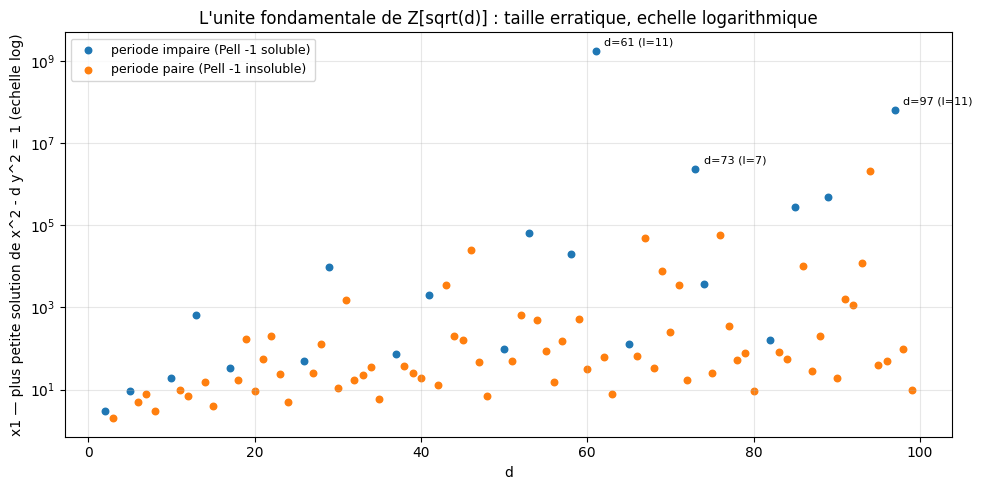

rang    d   l             x1
   1   61  11     1766319049
   2   97  11       62809633
   3   73   7        2281249
   4   94  16        2143295
   5   89   5         500001


In [7]:
import matplotlib.pyplot as plt

donnees = []
for d in range(2, 101):
    if est_carre(d):
        continue
    l = len(periode_sqrt(d))
    x1, _ = pell_minimale(d, 1)
    donnees.append((d, l, x1, l % 2 == 1))

fig, ax = plt.subplots(figsize=(10, 5))
for soluble in (True, False):
    sous = [t for t in donnees if t[3] == soluble]
    ax.scatter([t[0] for t in sous], [t[2] for t in sous],
               s=22, label="periode impaire (Pell -1 soluble)" if soluble
               else "periode paire (Pell -1 insoluble)")
ax.set_yscale("log")
ax.set_xlabel("d")
ax.set_ylabel("x1 — plus petite solution de x^2 - d y^2 = 1 (echelle log)")
ax.set_title("L'unite fondamentale de Z[sqrt(d)] : taille erratique, echelle logarithmique")
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left", fontsize=9)
for d, l, x1, _ in sorted(donnees, key=lambda t: -t[2])[:3]:
    ax.annotate(f"d={d} (l={l})", xy=(d, x1), xytext=(6, 4),
                textcoords="offset points", fontsize=8)
plt.tight_layout()
plt.show()

top = sorted(donnees, key=lambda t: -t[2])[:5]
print(f"{'rang':>4} {'d':>4} {'l':>3} {'x1':>14}")
for rang, (d, l, x1, _) in enumerate(top, 1):
    print(f"{rang:>4} {d:>4} {l:>3} {x1:>14}")

### Lecture du résultat

La figure est un nuage, non une courbe : à $d$ voisin, $x_1$ varie de plusieurs ordres de grandeur. Mais l'ordonnée est logarithmique, et c'est là que la structure apparaît — les trois records de la plage sont $d = 61$ ($x_1 = 1\,766\,319\,049$, période $11$), $d = 97$ ($62\,809\,633$, période $11$) et $d = 73$ ($2\,281\,249$, période $7$). Ce ne sont pas les plus grands $d$ : ce sont ceux dont la période est la plus longue.

C'est la raison d'être de tout l'appareil des sections 2 et 3. La taille de la solution minimale croît **exponentiellement en la longueur de la période**, elle-même de taille typiquement $\sqrt{d}$ mais sujette à des fluctuations considérables. Un algorithme qui cherche la solution directement est condamné ; un algorithme qui calcule la période la trouve en temps polynomial en $\log d$.

Le fait que les deux couleurs se répartissent indistinctement sur l'axe vertical est la marque que solubilité de $-1$ et taille de l'unité sont deux questions **indépendantes** : la parité décide de l'existence, la longueur décide de la taille.

## 7. Exemples guidés résolus et exercices

Les trois exemples guidés sont **résolus** ; chacun est suivi d'un exercice construit sur le **même instrument**, mais sur des paramètres différents — la convention de la série.

### Exemple guidé 1 — $d = 61$, la reine des petits $d$

Fermat posa en 1657 à Wallis et Brouncker le défi de résoudre $x^2 - 61\,y^2 = 1$ ; il fallut attendre Brouncker pour en voir la solution. Le parcours complet, tel que les sections précédentes l'ont construit :

1. calculer la période de $\sqrt{61}$, de longueur $\ell = 11$ ;
2. lire la solution de $-1$ au convergent $\ell - 1 = 10$ ;
3. en déduire la solution de $+1$ par élévation au carré ;
4. vérifier les deux normes, et la cohérence avec le convergent $2\ell - 1 = 21$.

In [8]:
d = 61
per = periode_sqrt(d)
l = len(per)
print(f"1. periode : {per}  (l = {l}, {'impaire' if l % 2 else 'paire'})")

neg = pell_minimale(d, -1)
print(f"2. solution de -1 : x = {neg[0]}, y = {neg[1]}"
      f"   (verif : {neg[0]**2 - d * neg[1]**2})")

carre = composer(neg, neg, d)
pos = pell_minimale(d, 1)
print(f"3. carre de la solution -1 : x = {carre[0]}, y = {carre[1]}")

convergent = convergents_sqrt(d, 2 * l - 1)[2 * l - 1]
print(f"4. convergent 2l-1 = 21 : ({convergent[0]}, {convergent[1]})")
print(f"   egal a la solution minimale : {carre == pos == convergent}")
print(f"   norme de la solution : {pos[0]**2 - d * pos[1]**2}")

1. periode : [1, 4, 3, 1, 2, 2, 1, 3, 4, 1, 14]  (l = 11, impaire)
2. solution de -1 : x = 29718, y = 3805   (verif : -1)
3. carre de la solution -1 : x = 1766319049, y = 226153980
4. convergent 2l-1 = 21 : (1766319049, 226153980)
   egal a la solution minimale : True
   norme de la solution : 1


### Exercice 1 — $d = 109$, l'autre défi de Fermat

Fermat posa le même défi avec $d = 109$ et $d = 181$ ; ces deux cas sont **considérablement plus durs** que $d = 61$, ce qui explique qu'il les ait posés. La solution de $d = 109$ a quinze chiffres.

Complétez la fonction pour qu'elle rende le parcours complet : période, solution de $-1$ ou son absence, solution de $+1$, vérification.

In [9]:
def exo1_parcours(d):
    """Parcours complet de Pell pour un d donne.

    Doit renvoyer un dictionnaire {periode, l, neg, pos, verif}.
    """
    # Etape 1 : calculer la periode et sa longueur.
    # Etape 2 : chercher la solution de cible -1 (elle peut ne pas exister).
    # Etape 3 : chercher la solution de cible +1.
    # Etape 4 : verifier x^2 - d y^2 = 1.
    # Indice : les fonctions periode_sqrt, pell_minimale et composer sont deja definies.
    resultat = None  # TODO etudiant
    return resultat


print("Exercice 1 a completer.")
res = exo1_parcours(109)
if res is not None:
    print(res)
    assert res["verif"] is True
    assert res["l"] == 15
    assert res["pos"][0] == 158070671986249
    print("Attendu : l = 15, x1 = 158070671986249 (15 chiffres), Pell -1 insoluble.")

Exercice 1 a completer.


### Exemple guidé 2 — $\sqrt{23}$ : palindrome, période paire, prédiction d'insolubilité

Le théorème de la section 4 permet de **prédire** sans calculer : si la période de $\sqrt{23}$ est paire, l'équation $x^2 - 23\,y^2 = -1$ est insoluble. Vérifions les deux volets — le palindrome, puis la prédiction.

In [10]:
d = 23
per = periode_sqrt(d)
coeur = per[:-1]
print(f"periode de sqrt(23) : {per}")
print(f"  sans le 2a0 final : {coeur}")
print(f"  palindrome : {coeur == coeur[::-1]}")
print(f"  longueur {len(per)} -> Pell -1 {'soluble' if len(per) % 2 else 'INSOLUBLE (prediction)'}")
mesure = pell_minimale(d, -1)
print(f"  mesure : {mesure if mesure else 'aucune solution'}")

l = len(per)
pos = pell_minimale(d, 1)
# l pair : la solution minimale est p_{l-1} ; l impair : p_{2l-1}
indice = l - 1 if l % 2 == 0 else 2 * l - 1
convergent = convergents_sqrt(d, indice)[indice]
print(f"  solution minimale de +1 : ({pos[0]}, {pos[1]})"
      f"  = convergent {indice} : {pos == convergent}")

periode de sqrt(23) : [1, 3, 1, 8]
  sans le 2a0 final : [1, 3, 1]
  palindrome : True
  longueur 4 -> Pell -1 INSOLUBLE (prediction)
  mesure : aucune solution
  solution minimale de +1 : (24, 5)  = convergent 3 : True


### Exercice 2 — composer les solutions de $d = 2$ par Brahmagupta

Toutes les solutions de $x^2 - 2y^2 = 1$ sont les puissances de $3 + 2\sqrt{2}$. Écrivez la fonction qui les énumère par composition successive, et vérifiez la norme à chaque étape.

In [11]:
def exo2_puissances(nmax):
    """Liste des n premieres puissances de (3 + 2 sqrt2), verifiees.

    Doit renvoyer une liste de triplets (n, x, y), norme verifiee = 1.
    """
    # Etape 1 : partir de l'unite fondamentale (3, 2).
    # Etape 2 : a chaque tour, composer avec (3, 2) via composer(u, (3, 2), 2).
    # Etape 3 : verifier x^2 - 2 y^2 == 1, sinon lever une exception.
    # Indice : la fonction composer(u, v, d) est deja definie.
    liste = None  # TODO etudiant
    return liste


print("Exercice 2 a completer.")
res = exo2_puissances(4)
if res is not None:
    print(res)
    assert res[1][1:] == (17, 12)
    assert res[3][1:] == (577, 408)
    print("Attendu : n=2 -> (17, 12), n=4 -> (577, 408).")

Exercice 2 a completer.


### Exemple guidé 3 — la table des records pour $d \leq 100$

Quels $d$ donnent les plus grandes unités fondamentales ? Le tri par $x_1$ décroissant répond, et la colonne $\ell$ explique.

In [12]:
donnees = []
for d in range(2, 101):
    if est_carre(d):
        continue
    l = len(periode_sqrt(d))
    x1, y1 = pell_minimale(d, 1)
    donnees.append((x1, d, l, "impaire" if l % 2 else "paire"))

donnees.sort(reverse=True)
print(f"{'rang':>4} {'d':>4} {'x1':>14} {'l':>3} {'parite':>8}")
for rang, (x1, d, l, parite) in enumerate(donnees[:6], 1):
    print(f"{rang:>4} {d:>4} {x1:>14} {l:>3} {parite:>8}")
print()
print(f"longueur de periode maximale sur d <= 100 : {max(t[2] for t in donnees)}"
      f" (atteinte pour {[t[1] for t in donnees if t[2] == max(u[2] for u in donnees)]})")

rang    d             x1   l   parite
   1   61     1766319049  11  impaire
   2   97       62809633  11  impaire
   3   73        2281249   7  impaire
   4   94        2143295  16    paire
   5   89         500001   5  impaire
   6   85         285769   5  impaire

longueur de periode maximale sur d <= 100 : 16 (atteinte pour [94])


### Exercice 3 — le critère de Legendre au-delà de 500, et le plus petit contre-exemple composé

Deux volets, sur l'instrument de la section 5 :

1. étendre la mesure du critère de Legendre aux premiers jusqu'à $2000$ et vérifier qu'il reste exact ;
2. trouver le **plus petit** entier composé $d$ dont tous les facteurs premiers valent $1 \pmod 4$ (ou valent $2$) et pour lequel la Pell négative est **insoluble**.

In [13]:
def exo3_critere_legendre(limite):
    """Verifie le critere de Legendre sur les premiers < limite.

    Doit renvoyer (nb_premiers_testes, liste_des_ecarts).
    """
    # Etape 1 : enumerer les premiers < limite.
    # Etape 2 : pour chacun, comparer (p % 4 == 1) a (pell_minimale(p, -1) is not None).
    # Etape 3 : collecter les desaccords.
    # Indice : est_premier et pell_minimale sont deja definies.
    resultat = None  # TODO etudiant
    return resultat


def exo3_plus_petit_compose(limite):
    """Plus petit compose dont tous les facteurs premiers valent 1 mod 4 (ou 2)
    et dont la Pell negative est insoluble."""
    # Etape 1 : enumerer les composes d croissants (d non carre).
    # Etape 2 : retenir ceux dont chaque facteur premier p verifie p == 1 mod 4 ou p == 2.
    # Etape 3 : tester pell_minimale(d, -1) ; rendre le premier insoluble.
    # Indice : facteurs_premiers(d) est deja definie.
    trouve = None  # TODO etudiant
    return trouve


print("Exercice 3 a completer.")
crit = exo3_critere_legendre(2000)
if crit is not None:
    print(f"Legendre < 2000 : {crit[0]} premiers, ecarts = {crit[1]}")
    assert crit[1] == []
compose = exo3_plus_petit_compose(200)
if compose is not None:
    print(f"plus petit compose contre-exemple : d = {compose}")
    assert compose == 34

Exercice 3 a completer.


## Conclusion

L'équation $x^2 - d\,y^2 = 1$ est le plus ancien problème d'arithmétique encore productif, et ce carnet en a mesuré toute la chaîne causale :

- **l'obstruction** est triviale — $d$ carré — et la solubilité, une fois l'obstruction levée, est **universelle** (Lagrange) ;
- **la taille** de la solution minimale, elle, est erratique : elle suit la longueur de la période de $\sqrt{d}$, et croît exponentiellement en elle ($d = 61$ : dix chiffres ; $d = 181$ : dix-neuf) ;
- **la fraction continue** fournit l'algorithme : le calcul se fait en temps polynomial en $\log d$, alors que la solution a une taille exponentielle ;
- **la parité de la période** décide de la solubilité de la Pell négative, avec une exactitude mesurée de $186/186$ sur $d \leq 200$ ;
- **le critère local** de Legendre est exact pour les premiers ($44/44$ et $0/50$ sous $500$ ; l'exercice 3 étend la mesure à $2000$) et cesse de suffire pour les composés ($d = 34$ en est le plus petit témoin) ;
- **la structure** est celle d'un groupe cyclique infini — Brahmagupta compose, les puissances épuisent, et le théorème de Dirichlet en donne le rang $1$.

Le pont avec les carnets [11](11-corps-quadratiques-reciprocite-quadratique.ipynb) et [15](15-quatre-carres-lagrange.ipynb) s'éclaire : les corps imaginaires ont des unités finies et un nombre de classes qui varie ; les corps réels ont des unités infinies et un nombre de classes qui, lui aussi, varie — mais l'unité fondamentale donne à leur arithmétique un invariant supplémentaire, le **régulateur** $\log$ de cette unité, dont la figure de la section 6 dessine l'ordre de grandeur.

## Ressources

**Sources primaires**

- Fermat, lettre à Wallis, février 1657 — l'énoncé du défi, avec les cas $d = 61, 109, 181$.
- Lagrange, *Solution d'un problème d'arithmétique* (1766-1770) — la preuve que l'équation a toujours une solution pour $d$ non carré.
- Bhāskara II, *Bījagaṇita*, XIIe siècle — la méthode **chakravala**, algorithme cyclique de résolution, six siècles avant Lagrange.
- H. W. Lenstra Jr., « Solving the Pell Equation », *Notices of the AMS* **49** (2002) — mise au point moderne, complexité, et histoire du problème des bœufs d'Archimède.

**Dans la série**

- Carnet [11](11-corps-quadratiques-reciprocite-quadratique.ipynb) — corps quadratiques imaginaires, réciprocité quadratique, le contraste fini/infini des groupes d'unités.
- Carnet [13](13-jacobi-kronecker-reciprocite-II.ipynb) — symbole de Kronecker, dont dépend le critère local de la section 5.
- Carnet [15](15-quatre-carres-lagrange.ipynb) — identité de Brahmagupta-Fibonacci, dont la loi de composition de la section 6 est l'application.
- Carnet [12](12-formes-quadratiques-binaires-nombre-classes.ipynb) et [14](14-formes-quadratiques-composition-gauss.ipynb) — la composition des formes, pendant du groupe de classes que le régulateur accompagne.

**Références en ligne**

- OEIS [A033313](https://oeis.org/A033313) — plus petites valeurs de $x$ pour $x^2 - ny^2 = 1$ ; OEIS [A033317](https://oeis.org/A033317) pour les $y$ correspondants.
- OEIS [A003285](https://oeis.org/A003285) — longueurs des périodes des fractions continues de $\sqrt{n}$, la suite même dont la section 6 montre le rôle.